In [ ]:
"The goal of this project is to predict YouTube Ad Revenue (ad_revenue_usd) using video performance metrics such as views, likes, comments, watch time, subscribers, category, device, and country."
# my best model is  Ridge Regression
# based on watch_time minute  ad_revenue is increased Both has good correlation
# all country revenue are equall
#  gaming has high likes
# music has high view 

In [2]:
import pandas as pd
import pickle


In [3]:
df=pd.read_csv(r"D:\datads\youtube_ad_revenue_dataset (6).csv")
df

,video_id,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd
0,vid_3092,2024-09-24 10:50:40.993199,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237
1,vid_3459,2024-09-22 10:50:40.993199,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508
2,vid_4784,2024-11-21 10:50:40.993199,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008
3,vid_4078,2025-01-28 10:50:40.993199,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261
4,vid_3522,2025-04-28 10:50:40.993199,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388
...,...,...,...,...,...,...,...,...,...,...,...,...
122395,vid_2902,2024-12-14 10:50:40.993199,9853,1673.0,147.0,42075.704885,25.490195,210818,Education,Tablet,US,280.986396
122396,vid_3890,2024-07-13 10:50:40.993199,10128,1709.0,63.0,57563.703040,16.229133,878860,Music,Desktop,UK,354.612981
122397,vid_3934,2024-06-10 10:50:40.993199,10267,700.0,NaN,27549.714659,23.822365,576756,Tech,Tablet,CA,203.643106
122398,vid_4260,2024-12-22 10:50:40.993199,10240,1616.0,106.0,56967.384382,7.753099,585138,Music,Mobile,UK,351.525811


In [3]:
df.columns

Index(['video_id', 'date', 'views', 'likes', 'comments', 'watch_time_minutes',
       'video_length_minutes', 'subscribers', 'category', 'device', 'country',
       'ad_revenue_usd'],
      dtype='object')

In [4]:
df.drop(['video_id'],axis=1)

,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd
0,2024-09-24 10:50:40.993199,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237
1,2024-09-22 10:50:40.993199,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508
2,2024-11-21 10:50:40.993199,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008
3,2025-01-28 10:50:40.993199,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261
4,2025-04-28 10:50:40.993199,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388
...,...,...,...,...,...,...,...,...,...,...,...
122395,2024-12-14 10:50:40.993199,9853,1673.0,147.0,42075.704885,25.490195,210818,Education,Tablet,US,280.986396
122396,2024-07-13 10:50:40.993199,10128,1709.0,63.0,57563.703040,16.229133,878860,Music,Desktop,UK,354.612981
122397,2024-06-10 10:50:40.993199,10267,700.0,NaN,27549.714659,23.822365,576756,Tech,Tablet,CA,203.643106
122398,2024-12-22 10:50:40.993199,10240,1616.0,106.0,56967.384382,7.753099,585138,Music,Mobile,UK,351.525811


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122400 entries, 0 to 122399
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   video_id              122400 non-null  object 
 1   date                  122400 non-null  object 
 2   views                 122400 non-null  int64  
 3   likes                 116283 non-null  float64
 4   comments              116288 non-null  float64
 5   watch_time_minutes    116295 non-null  float64
 6   video_length_minutes  122400 non-null  float64
 7   subscribers           122400 non-null  int64  
 8   category              122400 non-null  object 
 9   device                122400 non-null  object 
 10  country               122400 non-null  object 
 11  ad_revenue_usd        122400 non-null  float64
dtypes: float64(5), int64(2), object(5)
memory usage: 11.2+ MB


In [6]:
df.isnull().any()

video_id                False
date                    False
views                   False
likes                    True
comments                 True
watch_time_minutes       True
video_length_minutes    False
subscribers             False
category                False
device                  False
country                 False
ad_revenue_usd          False
dtype: bool

In [7]:
print(df.isnull().sum())

video_id                   0
date                       0
views                      0
likes                   6117
comments                6112
watch_time_minutes      6105
video_length_minutes       0
subscribers                0
category                   0
device                     0
country                    0
ad_revenue_usd             0
dtype: int64


In [68]:
df.shape

(122400, 12)

In [69]:
# null value columns --likes,comments,watch_time_minutes all are numeric columns



In [71]:
df['likes'].dtypes

dtype('float64')

In [72]:
df['watch_time_minutes'].dtypes

dtype('float64')

In [73]:
df['comments'].dtypes

dtype('float64')

# spliting the dataset into  feature and columns

In [9]:
X=df.drop(['ad_revenue_usd'],axis=1)
y=df['ad_revenue_usd']

print(X.shape)
print("__________________________________________________________________")
print(y.shape)
print("___________________________________________________________________________")

print (X.columns)
print("_______________________________________________________________________________")
print(y)

(122400, 11)
__________________________________________________________________
(122400,)
___________________________________________________________________________
Index(['video_id', 'date', 'views', 'likes', 'comments', 'watch_time_minutes',
       'video_length_minutes', 'subscribers', 'category', 'device', 'country'],
      dtype='object')
_______________________________________________________________________________
0         203.178237
1         140.880508
2         360.134008
3         224.638261
4         165.514388
             ...    
122395    280.986396
122396    354.612981
122397    203.643106
122398    351.525811
122399    253.842824
Name: ad_revenue_usd, Length: 122400, dtype: float64


# spliting the dataset into numeric and catgorical


In [10]:
numeric = X.select_dtypes(include=['int64','float64']).columns
catgorical = X.select_dtypes(include =['object']).columns

print(numeric)
print("__________________________________________________________________")
print(catgorical)

Index(['views', 'likes', 'comments', 'watch_time_minutes',
       'video_length_minutes', 'subscribers'],
      dtype='object')
__________________________________________________________________
Index(['video_id', 'date', 'category', 'device', 'country'], dtype='object')


# datavisuvalisation on null value columns

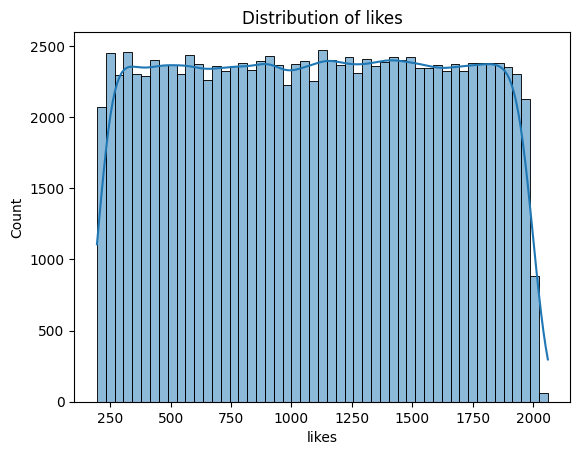

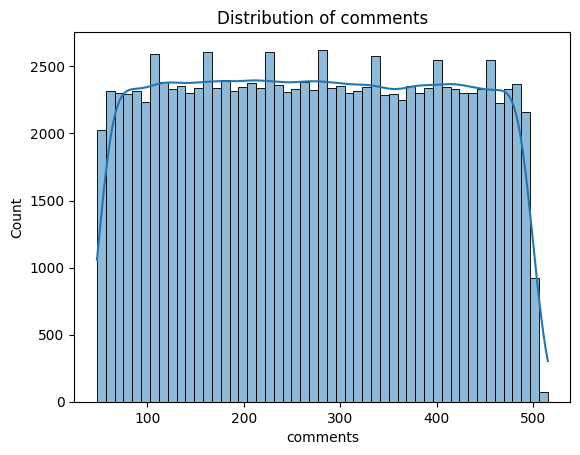

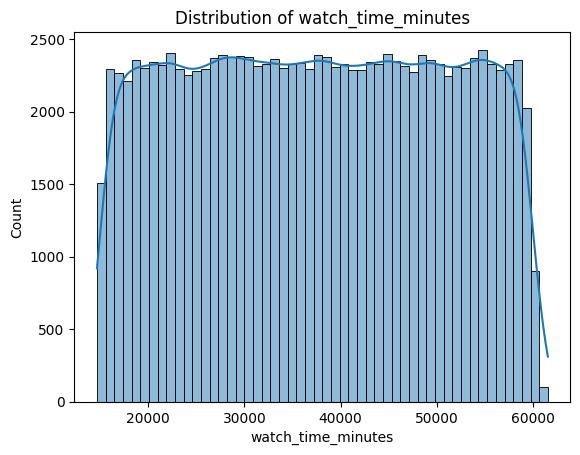

In [11]:

import seaborn as sns
import matplotlib.pyplot as plt

cols = ['likes', 'comments', 'watch_time_minutes']

for col in cols:
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

In [47]:
print("skew value for like",df['likes'].skew())
print("kurt value for like",df['likes'].kurt())

skew value for like -0.0027579035972128923
kurt value for like -1.1962956704335688


In [12]:

df['likes'].fillna(df['likes'].mean(),inplace = True)

In [14]:
print("skew value for comments ",df['comments'].skew())
print("kurt value for comments ",df['comments'].kurt())

skew value for comments  0.00793582575228909
kurt value for comments  -1.0982323077133385


In [13]:
df['comments'].fillna(df['comments'].mean(),inplace = True)

In [15]:
print("skew value for watch_time_minutes ",df['watch_time_minutes'].skew())
print("kurt value for watch_time_minutes ",df['watch_time_minutes'].kurt())

skew value for watch_time_minutes  0.0009027191329527335
kurt value for watch_time_minutes  -1.1944357188536434


In [16]:
df['watch_time_minutes'].fillna(df['watch_time_minutes'].mean(),inplace = True)

In [17]:
df.isnull().sum()

video_id                0
date                    0
views                   0
likes                   0
comments                0
watch_time_minutes      0
video_length_minutes    0
subscribers             0
category                0
device                  0
country                 0
ad_revenue_usd          0
dtype: int64

# checking the duplicates

In [18]:
print(df.duplicated().any())
print(df.duplicated().sum())

True
2400


In [19]:
df.drop_duplicates(inplace= True)

In [20]:

print(df.duplicated().sum())

0


# checking the outliers

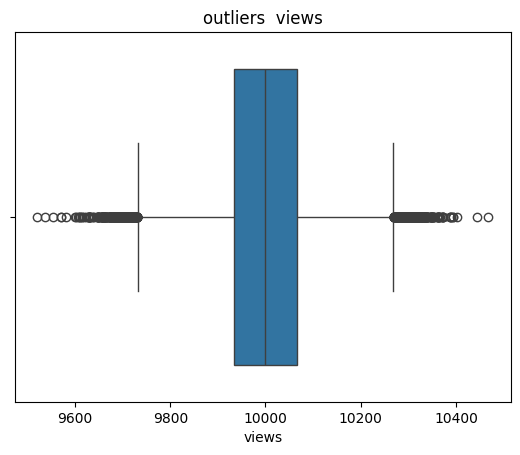

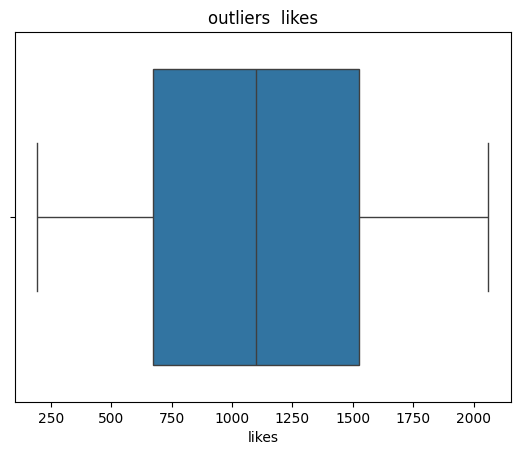

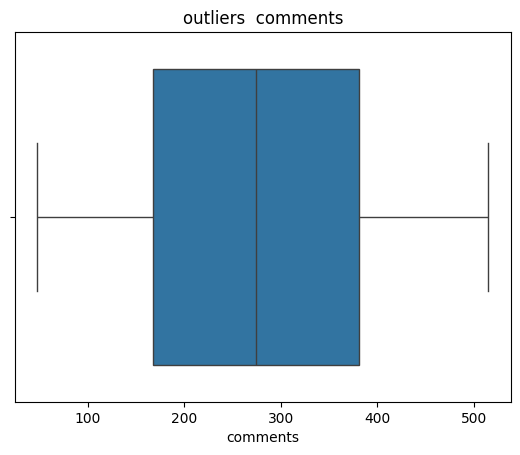

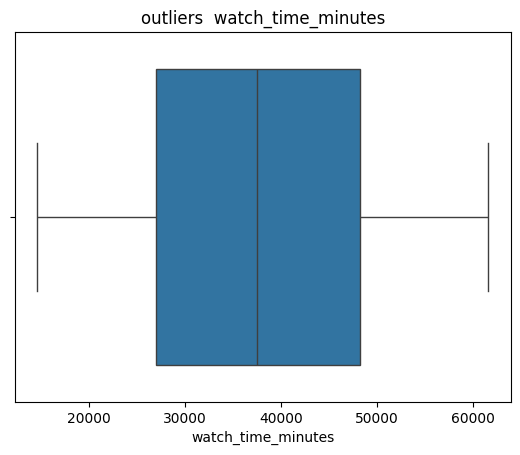

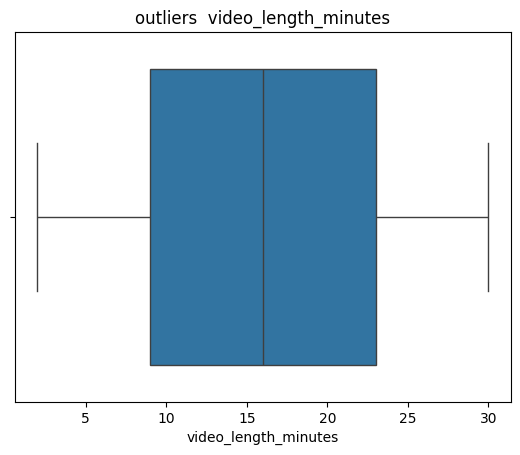

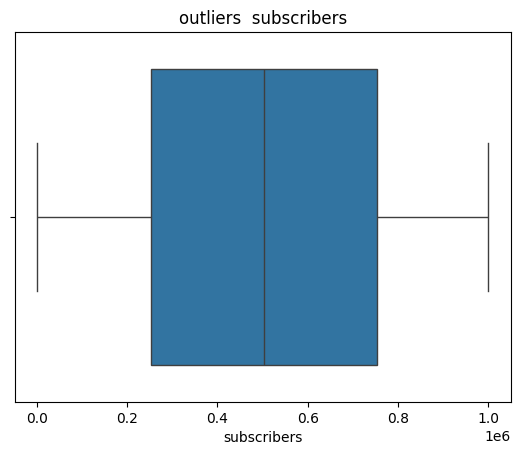

In [21]:
numeric = X.select_dtypes(include=['int64','float64']).columns

import seaborn as sns
import matplotlib.pyplot as plt


for col in numeric:
    sns.boxplot(x=df[col])
    plt.title(f'outliers  {col}')
    plt.show()


In [95]:
df['views'].skew()

np.float64(-0.0029119685491647124)

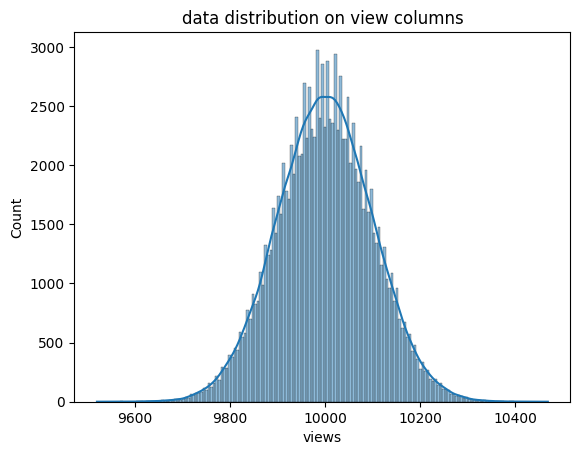

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['views'],kde =True)
plt.title("data distribution on view columns")
plt.show()



In [96]:
import numpy as np
mean_view = df['views'].mean()
std_view = df['views'].std()
z_score = (df['views']-mean_view)/std_view
df_clean = df[np.abs(z_score)<=3]

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (120000, 12)
Cleaned shape: (119684, 12)


# feather enginering 

In [23]:
df['like_rate'] = df['likes'] / (df['views']+1)
df['comment_rate'] = df['comments'] / (df['views']+1)
df['engagement_rate'] = (df['likes'] + df['comments']) / (df['views']+1)

df['revenue_per_view'] = df['ad_revenue_usd'] / (df['views']+1)
df['revenue_per_minute'] = df['ad_revenue_usd'] / (df['watch_time_minutes']+1)
df['likes_per_subscriber'] = df['likes'] / df['subscribers']
df['comments_per_subscriber'] = df['comments'] / df['subscribers']
df['views_pdf.er_subscriber'] = df['views'] / df['subscribers']

df.head()

,video_id,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd,like_rate,comment_rate,engagement_rate,revenue_per_view,revenue_per_minute,likes_per_subscriber,comments_per_subscriber,views_pdf.er_subscriber
0,vid_3092,2024-09-24 10:50:40.993199,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237,0.122874,0.032203,0.155077,0.020447,0.007668,0.005353,0.001403,0.043563
1,vid_3459,2024-09-22 10:50:40.993199,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508,0.064085,0.034538,0.098622,0.014063,0.009262,0.000872,0.000470,0.013610
2,vid_4784,2024-11-21 10:50:40.993199,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008,0.195979,0.018519,0.214498,0.035664,0.006281,0.008228,0.000777,0.041977
3,vid_4078,2025-01-28 10:50:40.993199,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261,0.118685,0.024116,0.142800,0.022385,0.007169,0.002741,0.000557,0.023094
4,vid_3522,2025-04-28 10:50:40.993199,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388,0.187867,0.048231,0.236097,0.016736,0.010565,0.044207,0.011349,0.235284


In [24]:
print(df.columns)

df.columns = df.columns.str.strip()

df['date'] = pd.to_datetime(df['date'], errors='coerce')

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['hour'] = df['date'].dt.hour
df['dayofweek'] = df['date'].dt.dayofweek

df.drop('date', axis=1, inplace=True)

Index(['video_id', 'date', 'views', 'likes', 'comments', 'watch_time_minutes',
       'video_length_minutes', 'subscribers', 'category', 'device', 'country',
       'ad_revenue_usd', 'like_rate', 'comment_rate', 'engagement_rate',
       'revenue_per_view', 'revenue_per_minute', 'likes_per_subscriber',
       'comments_per_subscriber', 'views_pdf.er_subscriber'],
      dtype='object')


# groupby 

In [25]:
df.groupby('category')[['views','likes','comments']].mean()



,views,likes,comments
category,,,
Education,9999.914078,1099.976182,275.750415
Entertainment,10000.106367,1096.888268,272.799917
Gaming,9999.773706,1104.980102,274.434101
Lifestyle,9999.808137,1093.727599,274.077691
Music,10000.379915,1101.692140,274.428432
Tech,9999.009986,1100.197850,274.612420


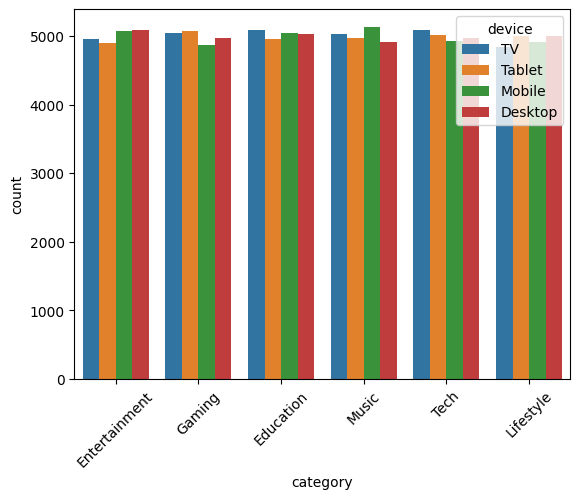

In [43]:
sns.countplot(x='category', hue='device', data=df)
plt.xticks(rotation=45)
plt.show()

In [44]:
df.groupby ('device')[['views','likes','comments']].mean()

,views,likes,comments
device,,,
Desktop,10000.599019,1092.718968,274.577383
Mobile,10000.172297,1100.545784,273.613583
TV,9999.290268,1103.131652,274.655236
Tablet,9999.268728,1101.944650,274.561918


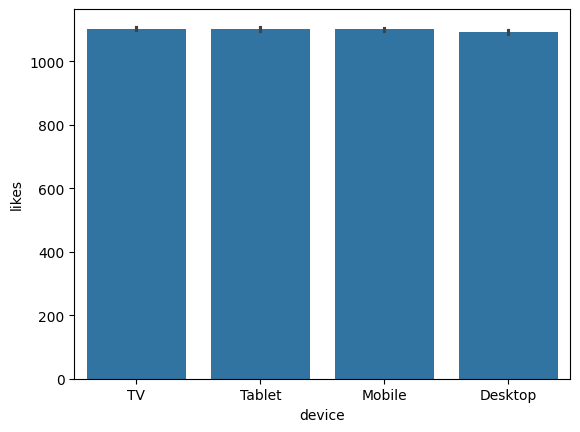

In [26]:
sns.barplot(x='device',y='likes', data=df)
plt.show()


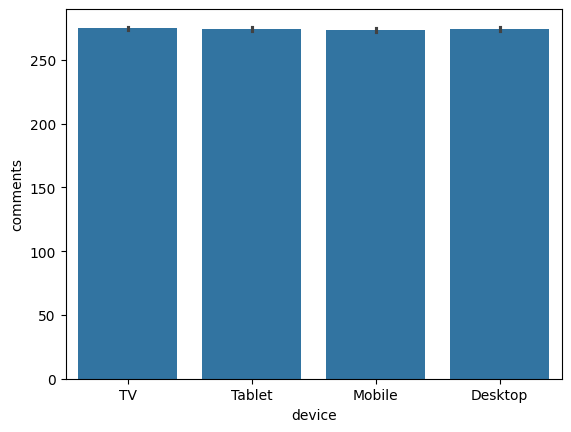

In [101]:
sns.barplot(x='device',y='comments', data=df)
plt.show()


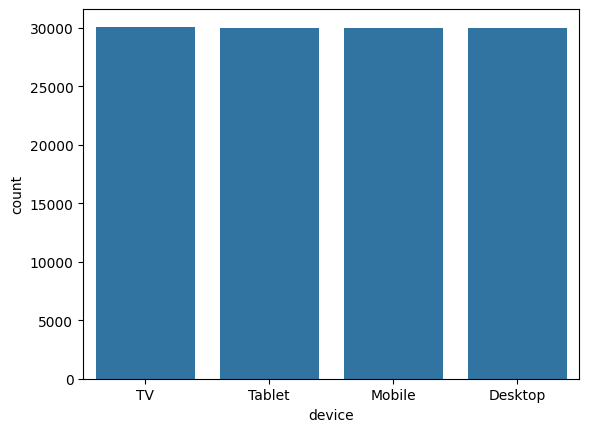

In [102]:

sns.countplot(x='device', data=df)
plt.show()

In [103]:
df.groupby('country')[['views','likes','comments']].mean()


,views,likes,comments
country,,,
AU,10000.029582,1099.182681,273.930593
CA,9999.720418,1102.395255,274.524666
DE,9999.821032,1098.018728,274.404246
IN,10000.251935,1098.217947,275.328529
UK,9998.633992,1104.509666,274.361126
US,10000.540697,1095.149970,273.539441


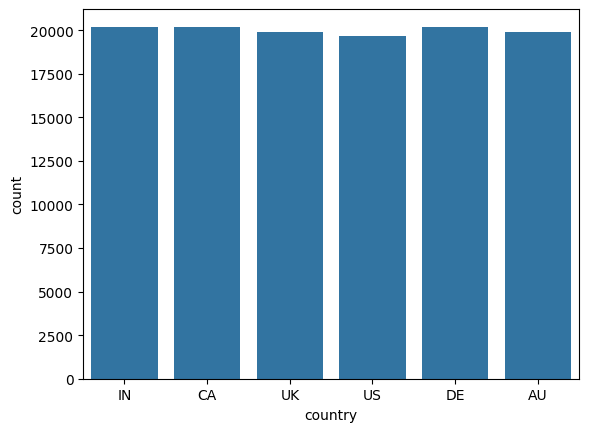

In [50]:
sns.countplot(x='country', data=df)
plt.show()

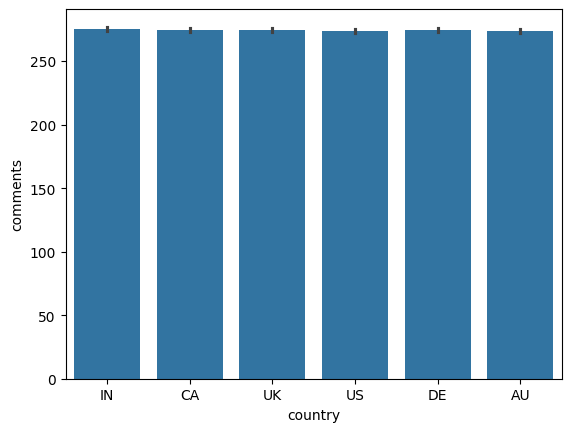

In [105]:
sns.barplot(x='country', y='comments', data=df)
plt.show()

# spliting the dataset into train_test _split

In [27]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size =0.2)

# encoding


In [28]:
from sklearn .preprocessing import  StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric = X.select_dtypes(include=['int64','float64']).columns
catgorical = X.select_dtypes(include =['object']).columns


preprocessing = ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numeric),
        ("cat",OneHotEncoder(handle_unknown="ignore",),catgorical)

        
    ]
    )

X_train_enc = preprocessing.fit_transform(X_train)
X_test_enc = preprocessing.fit_transform(X_test)

In [29]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate numeric and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns


num_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="mean")),
    ("scaler",StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder())
])


preprocessing = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)

    ]
)
X_train_enc = preprocessing.fit_transform(X_train)
X_test_enc = preprocessing.transform(X_test)

# regression 

In [32]:
import numpy as np
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

linear = LinearRegression()
linear.fit(X_train_enc,y_train)

train_predict = linear.predict(X_train_enc)
test_predict = linear.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 0.9523589115281695
rmse 13.521197068183339
 mae 4.966825712630569
**********test************
r2 0.9505118939578302
rmse 13.791023266656188
 mae 5.096693339933339


In [33]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

lasso = Lasso()
lasso.fit(X_train_enc,y_train)

train_predict = lasso.predict(X_train_enc)
test_predict = lasso.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 0.9486414966307459
rmse 14.0388160858976
 mae 4.471096368283436
**********test************
r2 0.9524147855650512
rmse 13.523281547213335
 mae 4.31985435545229


In [34]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

ridge= Ridge()
ridge.fit(X_train_enc,y_train)

train_predict = ridge.predict(X_train_enc)
test_predict = ridge.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 0.9523445214489151
rmse 13.523238965348625
 mae 4.884363024632371
**********test************
r2 0.9508423682299272
rmse 13.744898925262895
 mae 4.9863864603791574


In [35]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

dt= DecisionTreeRegressor()
dt.fit(X_train_enc,y_train)

train_predict = dt.predict(X_train_enc)
test_predict = dt.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 1.0
rmse 0.0
 mae 0.0
**********test************
r2 0.9147647028556624
rmse 18.09905143703428
 mae 4.832866117401893


In [110]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score ,mean_absolute_error,mean_squared_error

rf= RandomForestRegressor( n_estimators=10,random_state=42)
rf.fit(X_train_enc,y_train)

train_predict = rf.predict(X_train_enc)
test_predict = rf.predict(X_test_enc)


print("**********train************")
print("r2",r2_score(y_train, train_predict))
print("rmse", np.sqrt(mean_squared_error(y_train, train_predict)))
print(" mae", mean_absolute_error(y_train, train_predict))

print("**********test************")

print("r2",r2_score(y_test, test_predict))
print("rmse", np.sqrt(mean_squared_error(y_test,test_predict)))
print(" mae", mean_absolute_error(y_test, test_predict))

**********train************
r2 0.9903084778537606
rmse 6.101815939074456
 mae 1.5673975292482243
**********test************
r2 0.9455765349993311
rmse 14.429929996012023
 mae 3.945306772909409


In [4]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge

scores = {
    "linearRegression": 0.9510604537091444,
    "lasso": 0.9502735222630861,
    "ridge": 0.9510639579659419,
    "DecisionTreeRegressor": 0.9101011494858107,
    "randomforestregression": 0.9455765349993311
}

# Find the best model name based on the highest score
best_model_name = max(scores, key=scores.get)

# Print the results correctly
print("\nBest Model:", best_model_name)
print("Best Score:", scores[best_model_name])


Best Model: ridge
Best Score: 0.9510639579659419


In [ ]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score
import pandas as pd
import pickle


df = pd.read_csv(r"D:\datads\youtube_ad_revenue_dataset (6).csv")

X = df.drop(['ad_revenue_usd'], axis=1)
y = df['ad_revenue_usd']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

#  Build Pipelines
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessing = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ]
)

# 5. Transform Data properly (Fit on train, transform on test)
X_train_enc = preprocessing.fit_transform(X_train)
X_test_enc = preprocessing.transform(X_test)

# 6. Initialize Models
models = {
    "linearRegression": LinearRegression(),
    "lasso": Lasso(),
    "ridge": Ridge(),
    "DecisionTreeRegressor": DecisionTreeRegressor(),
    "randomforestregression": RandomForestRegressor()
}

# 7. Train Models and Evaluate Scores
scores = {}
for name, model in models.items():
    model.fit(X_train_enc, y_train)
    y_pred = model.predict(X_test_enc)
    scores[name] = r2_score(y_test, y_pred)

print("Scores:", scores)

# 8. Find the Best Model Name (Crucial step that was missing)
best_model_name = max(scores, key=scores.get)
print(f"\nBest Model: {best_model_name} with R2 Score: {scores[best_model_name]}")

best_model = models[best_model_name]

# 9. Save the Best Model
with open("model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully!")




with open("model.pkl", "rb") as file:
    model = pickle.load(file)

with open("preprocessing.pkl", "rb") as file:
    preprocessing = pickle.load(file)

In [ ]:
import streamlit as st
import pandas as pd
import pickle

# Load model and preprocessing
with open("model.pkl", "rb") as file:
model = pickle.load(file)

with open("preprocessing.pkl", "rb") as file:
preprocessing = pickle.load(file)

# Title
st.title("Content Monetization Modeler")
st.write("Predict YouTube Ad Revenue")

# User Inputs
video_id = st.text_input("Video ID")

views = st.number_input("Views", min_value=0)
likes = st.number_input("Likes", min_value=0)
comments = st.number_input("Comments", min_value=0)
watch_time_minutes = st.number_input("Watch Time Minutes", min_value=0.0)
video_length_minutes = st.number_input("Video Length Minutes", min_value=0.0)
subscribers = st.number_input("Subscribers", min_value=0)

category = st.selectbox("Category",["Education", "Gaming", "Music", "Entertainment"])

device = st.selectbox("Device",["Mobile", "Desktop", "Tablet"])

country = st.selectbox("Country",["USA", "India", "UK", "Canada", "Australia"])

date = st.date_input("Upload Date")

# Prediction
if st.button("Predict Revenue"):

input_data = pd.DataFrame({
"video_id": [video_id],
"date": [str(date)],
"views": [views],
"likes": [likes],
"comments": [comments],
"watch_time_minutes": [watch_time_minutes],
"video_length_minutes": [video_length_minutes],
"subscribers": [subscribers],
"category": [category],
"device": [device],
"country": [country]
})

# Transform input
input_enc = preprocessing.transform(input_data)

# Predict
prediction = model.predict(input_enc)

st.success(f"Predicted Ad Revenue: ${prediction[0]:.2f}")




Python
df['years'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['dayofweek'] = df['date'].dt.dayofweek


In [4]:
df['category']

0         Entertainment
1                Gaming
2             Education
3         Entertainment
4             Education
              ...      
122395        Education
122396            Music
122397             Tech
122398            Music
122399             Tech
Name: category, Length: 122400, dtype: object

In [5]:
df['category'].unique()

array(['Entertainment', 'Gaming', 'Education', 'Music', 'Tech',
       'Lifestyle'], dtype=object)

In [7]:
# which category have high revenue
df.groupby('category')['ad_revenue_usd'].mean().sort_values(ascending=False)

category
Gaming           253.507619
Tech             253.473340
Music            252.587527
Education        252.481643
Entertainment    252.445854
Lifestyle        251.860649
Name: ad_revenue_usd, dtype: float64

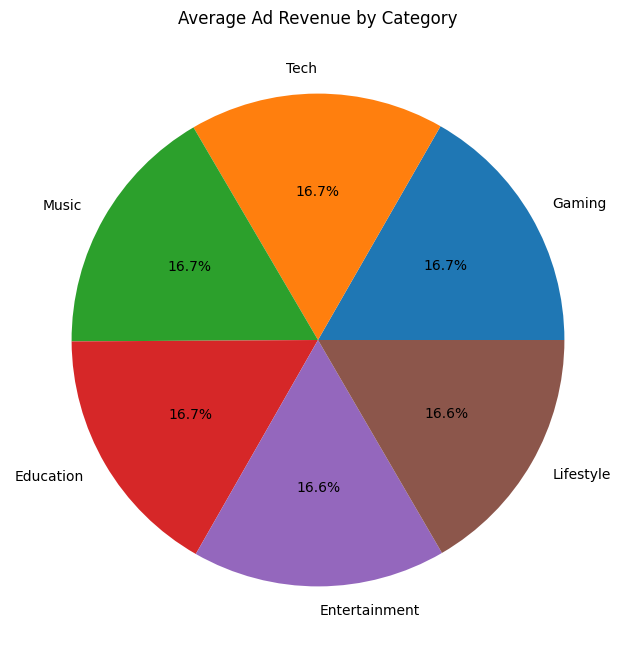

In [16]:
category_revenue = (df.groupby('category')['ad_revenue_usd'].mean().sort_values(ascending=False))

plt.figure(figsize=(8,8))

plt.pie(category_revenue,labels=category_revenue.index,autopct='%1.1f%%')

plt.title("Average Ad Revenue by Category")

plt.show()

In [8]:
# which category has high view

df.groupby('category')['views'].mean().sort_values(ascending = False)

category
Music            10000.380122
Entertainment    10000.192249
Gaming            9999.939044
Education         9999.902311
Lifestyle         9999.697628
Tech              9999.024359
Name: views, dtype: float64

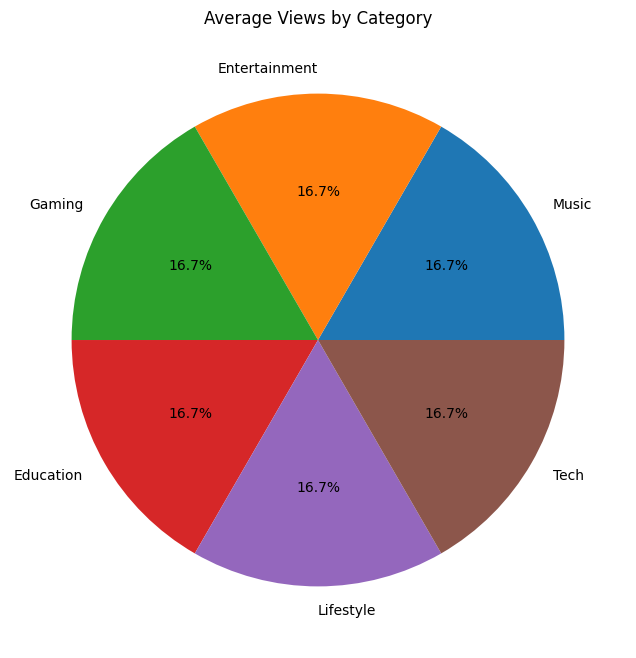

In [14]:
import matplotlib.pyplot as plt

category_views = (df.groupby('category')['views'].mean().sort_values(ascending=False))

plt.figure(figsize=(8,8))

plt.pie(category_views,labels=category_views.index,autopct='%1.1f%%')

plt.title("Average Views by Category")
plt.show()

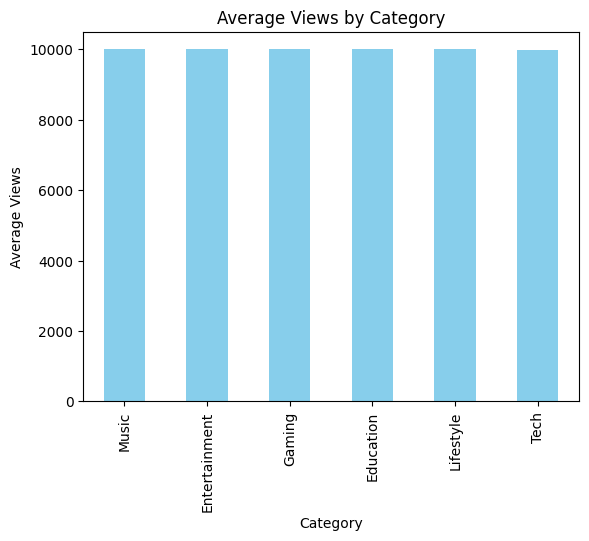

In [15]:
category_views.plot(kind='bar',color='skyblue')

plt.title("Average Views by Category")
plt.xlabel("Category")
plt.ylabel("Average Views")
plt.show()

In [9]:
# which category has high likes

df.groupby('category')['likes'].mean().sort_values(ascending=False)

category
Gaming           1105.850116
Music            1101.297100
Tech             1100.462975
Education        1100.376056
Entertainment    1096.311442
Lifestyle        1093.448359
Name: likes, dtype: float64

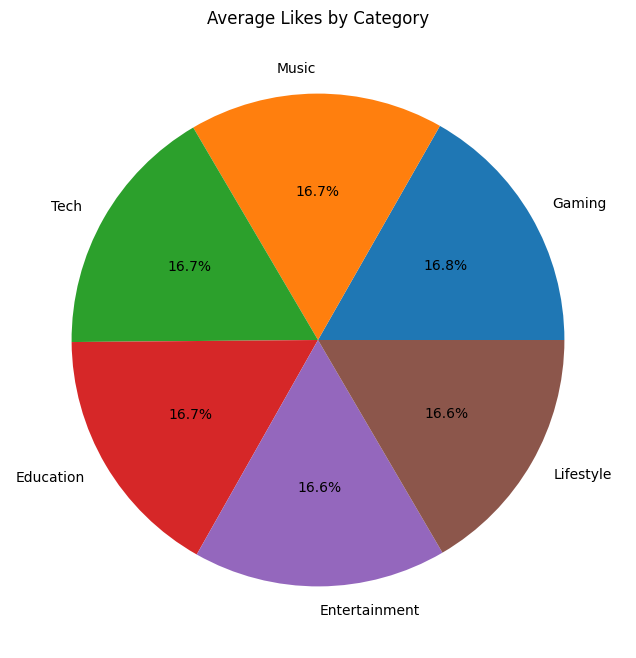

In [ ]:
import matplotlib.pyplot as plt

category_likes = (df.groupby('category')['likes'].mean().sort_values(ascending=False))

plt.figure(figsize=(8,8))

plt.pie(category_likes,labels=category_likes.index,autopct='%1.1f%%')

plt.title("Average Likes by Category")
plt.show()
#  gaming has high likes


In [12]:
# which category has hight watch time
df.groupby('category')['watch_time_minutes'].mean().sort_values(ascending=False)

category
Gaming           37709.664614
Tech             37706.514147
Music            37505.133494
Entertainment    37489.253736
Education        37479.092117
Lifestyle        37372.160790
Name: watch_time_minutes, dtype: float64

In [13]:
# which country as high revenue
df.groupby('country')['ad_revenue_usd'].mean().sort_values(ascending=False)

country
US    253.215380
CA    252.817583
DE    252.745599
IN    252.598216
AU    252.539689
UK    252.452118
Name: ad_revenue_usd, dtype: float64

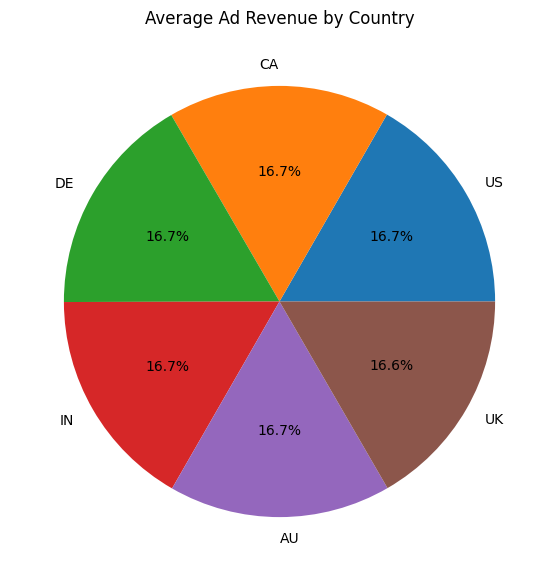

In [ ]:
import matplotlib.pyplot as plt

country_revenue = (df.groupby('country')['ad_revenue_usd'].mean().sort_values(ascending=False))

plt.figure(figsize=(7,7))

plt.pie(country_revenue,labels=country_revenue.index,autopct='%1.1f%%')

plt.title("Average Ad Revenue by Country")
plt.show()
# here all country revenue are equall

In [14]:
df.groupby('device')['ad_revenue_usd'].mean()

device
Desktop    252.341229
Mobile     253.275517
TV         252.287189
Tablet     253.005502
Name: ad_revenue_usd, dtype: float64

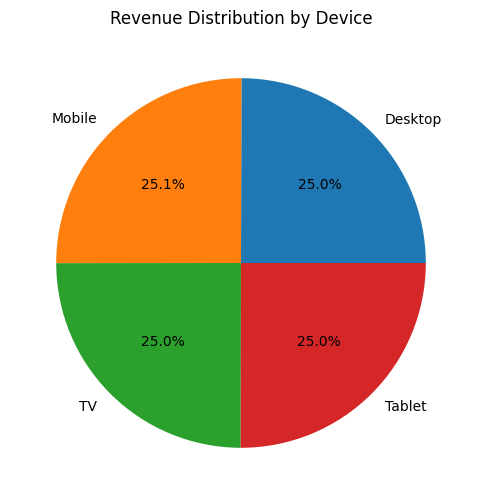

In [9]:
device_revenue = df.groupby('device')['ad_revenue_usd'].mean()

plt.figure(figsize=(6,6))

plt.pie( device_revenue,labels=device_revenue.index,autopct='%1.1f%%')

plt.title("Revenue Distribution by Device")
plt.show()

In [16]:
# most liked vedio
df.loc[df['likes'].idxmax()]

video_id                                  vid_1639
date                    2024-09-30 10:50:40.993199
views                                        10326
likes                                       2061.0
comments                                     113.0
watch_time_minutes                    25708.213137
video_length_minutes                     22.481998
subscribers                                  34778
category                                 Education
device                                      Mobile
country                                         US
ad_revenue_usd                           212.37011
Name: 44037, dtype: object

In [ ]:
# mosted viewed vedio
df.loc[df['views'].idxmax()]

video_id                                  vid_4663
date                    2025-02-28 10:50:40.993199
views                                        10468
likes                                       1696.0
comments                                     207.0
watch_time_minutes                    25285.678819
video_length_minutes                     17.924853
subscribers                                 574547
category                                 Lifestyle
device                                          TV
country                                         CA
ad_revenue_usd                          206.460161
Name: 93730, dtype: object

In [ ]:
# lessely viewed vedio
df.loc[df['views'].idxmin()]

video_id                                  vid_2114
date                    2024-09-21 10:50:40.993199
views                                         9521
likes                                       1123.0
comments                                     359.0
watch_time_minutes                    23371.468848
video_length_minutes                     22.883024
subscribers                                 485678
category                                 Education
device                                     Desktop
country                                         US
ad_revenue_usd                          185.265432
Name: 4146, dtype: object

In [20]:
df['views'].idxmax()

93730

In [21]:
# mosted commented vedio
df.loc[df['comments'].idxmax()]

video_id                                  vid_4105
date                    2024-07-05 10:50:40.993199
views                                        10324
likes                                       1686.0
comments                                     515.0
watch_time_minutes                    51787.924151
video_length_minutes                     22.702523
subscribers                                 292102
category                                     Music
device                                      Tablet
country                                         UK
ad_revenue_usd                          335.777476
Name: 109818, dtype: object

In [22]:
# highest revenue vedio
df['ad_revenue_usd'].idxmax()

115067

In [23]:
df.loc[df['ad_revenue_usd'].idxmax()]

video_id                                  vid_3708
date                    2024-11-07 10:50:40.993199
views                                        10198
likes                                       2028.0
comments                                     375.0
watch_time_minutes                    61157.975673
video_length_minutes                      5.067021
subscribers                                 528766
category                                      Tech
device                                     Desktop
country                                         UK
ad_revenue_usd                          382.768254
Name: 115067, dtype: object

In [ ]:
# lowest revenue vedio
df.loc[df['ad_revenue_usd'].idxmin()]

video_id                                  vid_2182
date                    2024-11-19 10:50:40.993199
views                                         9874
likes                                        241.0
comments                                      67.0
watch_time_minutes                      14815.7704
video_length_minutes                       3.53417
subscribers                                 400281
category                                     Music
device                                      Tablet
country                                         CA
ad_revenue_usd                          126.590603
Name: 71148, dtype: object

In [25]:
df['ad_revenue_usd'].idxmin()

71148

In [27]:
# finding revenue and subriber
df[['subscribers','ad_revenue_usd']].corr()

,subscribers,ad_revenue_usd
subscribers,1.000000,0.005907
ad_revenue_usd,0.005907,1.000000


In [ ]:
df.groupby('country')['ad_revenue_usd'].mean().sort_values(ascending=False)

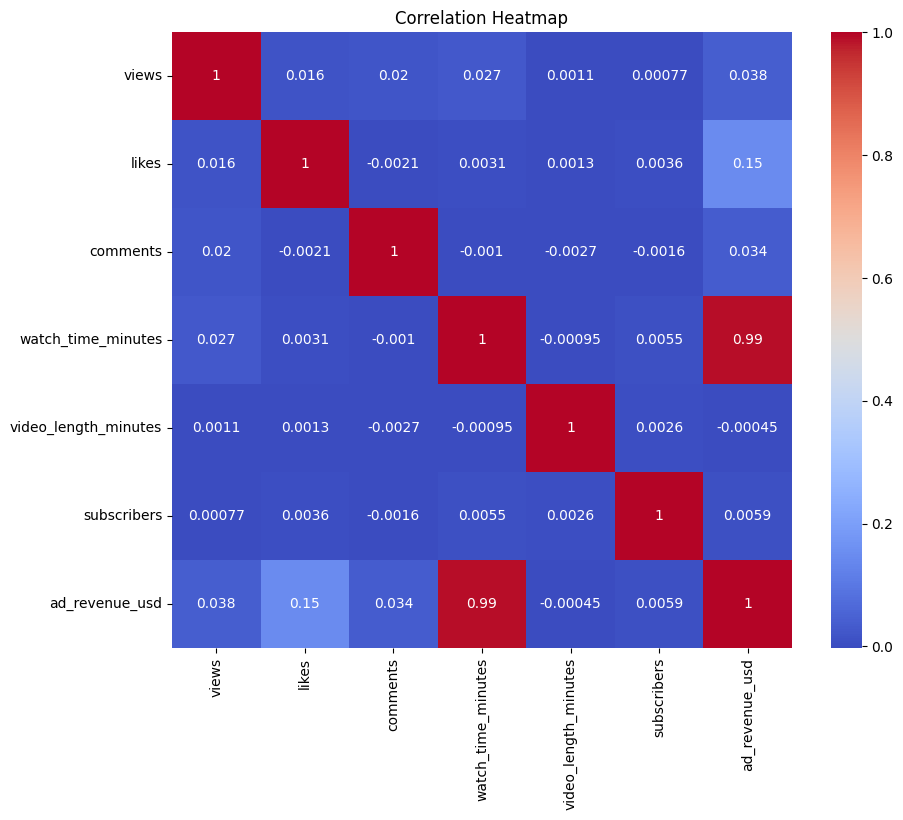

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = df.select_dtypes(include=['int64','float64']).corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


In [ ]:
# based on watch_time minute  ad_revenue is increased

In [ ]:
corr = df.corr(numeric_only=True)

print(corr['ad_revenue_usd'].sort_values(ascending=False))

ad_revenue_usd          1.000000
watch_time_minutes      0.988874
likes                   0.146449
views                   0.038497
comments                0.034274
subscribers             0.005907
video_length_minutes   -0.000446
Name: ad_revenue_usd, dtype: float64
